# Personas de 65 años o más por cada 100 en edad de trabajar

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "tasa-dependencia-mayores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Personas de 65 años o más por cada 100 en edad de trabajar"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "personas de 65 años o más por cada 100 de 15 a 64 años"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántas personas de 65 años o más hay por cada 100 personas de 15 a 64 años, la llamada *tasa de dependencia de las personas mayores*. Es la relación entre el tamaño del grupo de edad que suele cobrar pensión de jubilación y el del grupo en edad de trabajar.

**Cómo se lee.** Un valor de 30 significa que hay 30 personas de 65 años o más por cada 100 de 15 a 64 años, es decir, algo más de 3 personas en edad de trabajar por cada persona mayor.

**Limitaciones.**
- **Es un indicador demográfico.** No cuenta cuántas personas de cada grupo trabajan o cobran una pensión: no todas las personas de 15 a 64 años trabajan ni todas las de 65 o más están jubiladas. La relación entre quienes cotizan y quienes cobran en España está en `afiliados-por-pensionista`.
- Las edades son convencionales: la edad legal de jubilación en España sube de forma gradual hasta los 67 años en 2027.
- **Dos fuentes.** Eurostat da la población a 1 de enero; el Banco Mundial, que publica las estimaciones de Naciones Unidas (*World Population Prospects*), la población a mitad de año, y para los últimos años son estimaciones que se revisan en cada edición. La sección 3 compara las dos para España.
- Las proyecciones de población quedan fuera de esta gráfica; las que usan las proyecciones del gasto en pensiones se citan en `proyeccion-gasto-pensiones`.

## 2. Descarga

- **España y UE-27:** Eurostat, indicadores de estructura de la población (`demo_pjanind`), `OLDDEP1` (población de 65 años o más entre la de 15 a 64, por 100), a 1 de enero.
- **OCDE, EE. UU. y Canadá:** Banco Mundial, `SP.POP.DPND.OL` (misma definición, población a mitad de año; fuente: Naciones Unidas, *World Population Prospects*). La media de la OCDE es el agregado `OED` (miembros de la OCDE).
- **Comprobación:** el mismo indicador del Banco Mundial para España y la Unión Europea, para compararlo con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, worldbank
from lib.tipos import FuenteMeta

eu, fuentes_eu = eurostat.get("demo_pjanind", {"freq": "A", "indic_de": "OLDDEP1"}, desde=DESDE)
INDICADOR_BM = "SP.POP.DPND.OL"
bm, fuentes_bm = worldbank.get(
    INDICADOR_BM,
    paises={"OED": "ocde", "USA": "eeuu", "CAN": "canada", "ESP": "espana_bm", "EUU": "ue27_bm"},
    desde=DESDE,
)
print(eu.groupby("serie")["periodo"].agg(["min", "max"]), bm.groupby("serie")["periodo"].agg(["min", "max"]), sep="\n")

         min   max
serie             
espana  1976  2025
ue27    2001  2025
            min   max
serie                
canada     1976  2025
eeuu       1976  2025
espana_bm  1976  2025
ocde       1976  2025
ue27_bm    1976  2025


## 3. Transformación

Sin transformación: las dos fuentes publican el indicador por cada 100 personas de 15 a 64 años. España y la UE-27 salen de Eurostat; la OCDE, EE. UU. y Canadá, del Banco Mundial.

In [ ]:
df = pd.concat([eu, bm[bm["serie"].isin(["ocde", "eeuu", "canada"])]], ignore_index=True)
fuentes = [
    FuenteMeta(f.serie, f.organismo, "demo_pjanind (indic_de=OLDDEP1)", f.url, f.fecha_consulta) for f in fuentes_eu
] + [f for f in fuentes_bm if f.serie in ("ocde", "eeuu", "canada")]
assert df["valor"].between(5, 80).all(), "valor fuera de rango: ¿unidades?"


def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
comp = pd.DataFrame({
    "España Eurostat": serie(eu, "espana"), "España BM": serie(bm, "espana_bm"),
    "UE-27 Eurostat": serie(eu, "ue27"), "UE BM": serie(bm, "ue27_bm"),
})
comp["dif. España (BM − Eurostat)"] = comp["España BM"] - comp["España Eurostat"]
display(comp.loc[DESDE:].round(1).iloc[::5])
display(comp.round(1).tail(6))
dif = comp["dif. España (BM − Eurostat)"].dropna()
DIF_MAX, ANIO_DIF_MAX = dif.abs().max(), int(dif.abs().idxmax())
DIF_ULT, ANIO_ULT = dif.iloc[-1], int(dif.index[-1])
HASTA_2019 = dif.loc[:2019].abs().max()

,España Eurostat,España BM,UE-27 Eurostat,UE BM,dif. España (BM − Eurostat)
periodo,,,,,
1976,16.7,16.8,NaN,19.6,0.1
1981,17.8,17.8,NaN,19.9,0.0
1986,18.6,18.7,NaN,19.1,0.1
1991,20.6,20.7,NaN,20.5,0.1
1996,22.4,22.5,NaN,22.0,0.1
2001,24.5,24.5,23.4,23.6,0.0
2006,24.2,24.0,25.1,25.3,-0.2
2011,25.2,25.3,26.6,26.8,0.1
2016,28.2,28.3,29.6,29.8,0.1


,España Eurostat,España BM,UE-27 Eurostat,UE BM,dif. España (BM − Eurostat)
periodo,,,,,
2020,29.5,29.5,32.0,32.1,0.0
2021,29.7,29.9,32.6,32.7,0.2
2022,30.2,30.5,33.1,33.3,0.3
2023,30.4,31.3,33.4,33.9,0.9
2024,30.8,32.1,33.9,34.6,1.3
2025,31.2,32.9,34.5,35.4,1.7


### Notas

In [ ]:
NOTAS = [
    "España y UE-27: Eurostat, indicadores de estructura de la población (demo_pjanind, OLDDEP1): población de 65 "
    "años o más entre la de 15 a 64, por 100, a 1 de enero. Media UE-27: agregado de composición actual "
    "(EU27_2020).",
    "OCDE, EE. UU. y Canadá: Banco Mundial (SP.POP.DPND.OL), con la misma definición y la población a mitad de año "
    "según las estimaciones de Naciones Unidas (World Population Prospects); la media de la OCDE es el agregado de "
    "los países miembros (OED) que calcula el Banco Mundial.",
    f"España en las dos fuentes: la diferencia entre el Banco Mundial y Eurostat no pasa de {fmt(HASTA_2019)} puntos "
    f"hasta 2019, pero llega a {fmt(DIF_MAX)} en {ANIO_DIF_MAX}"
    + ("" if ANIO_DIF_MAX == ANIO_ULT else f" ({fmt(DIF_ULT)} en {ANIO_ULT})")
    + ". Para los últimos años, las cifras de Naciones Unidas que publica el Banco Mundial son estimaciones que se "
    "revisan en cada edición; las series de la OCDE, EE. UU. y Canadá pueden cambiar por el mismo motivo.",
    "Es un indicador demográfico: no cuenta cuántas personas de cada grupo de edad trabajan o cobran una pensión.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, indicadores de estructura de la población (demo_pjanind, OLDDEP1): población de 65 años o más entre la de 15 a 64, por 100, a 1 de enero. Media UE-27: agregado de composición actual (EU27_2020).
- OCDE, EE. UU. y Canadá: Banco Mundial (SP.POP.DPND.OL), con la misma definición y la población a mitad de año según las estimaciones de Naciones Unidas (World Population Prospects); la media de la OCDE es el agregado de los países miembros (OED) que calcula el Banco Mundial.
- España en las dos fuentes: la diferencia entre el Banco Mundial y Eurostat no pasa de 0,3 puntos hasta 2019, pero llega a 1,7 en 2025. Para los últimos años, las cifras de Naciones Unidas que publica el Banco Mundial son estimaciones que se revisan en cada edición; las series de la OCDE, EE. UU. y Canadá pueden cambiar por el mismo motivo.
- Es un indicador demográfico: no cuenta cuántas personas de cada grupo de edad trabajan o cobran una pensión.


## 4. Visualización

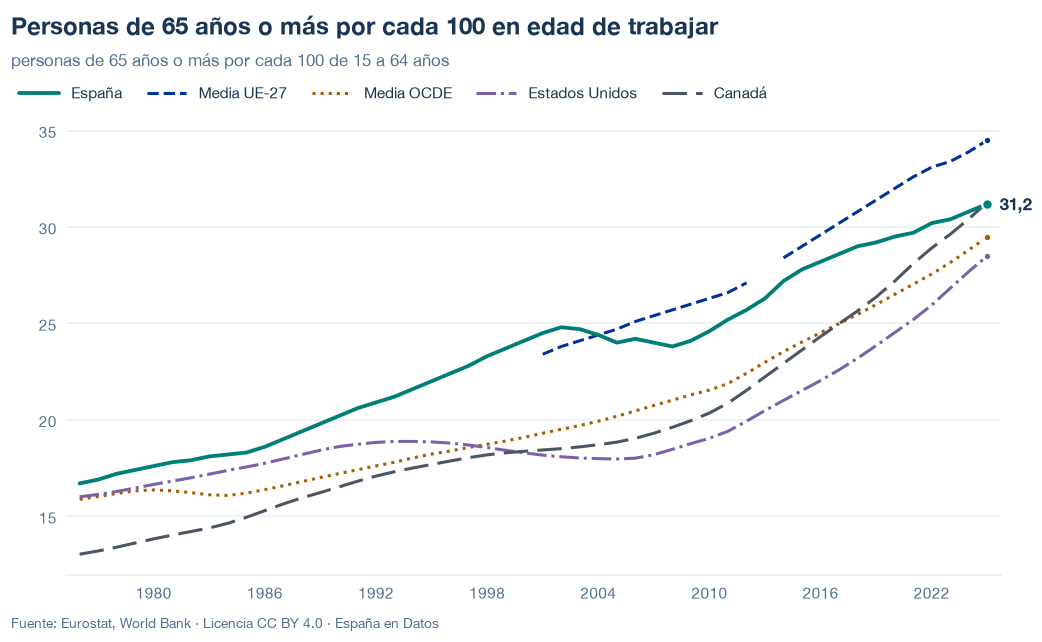

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-dependencia-mayores.json y data/tasa-dependencia-mayores.csv


## 6. Fuentes, notas y licencia

- Eurostat, `demo_pjanind` (`OLDDEP1`): España y UE-27.
- Banco Mundial, `SP.POP.DPND.OL`: OCDE (`OED`), EE. UU. y Canadá; España y la UE (`EUU`) solo para la comprobación.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.